# Analisis penjualan toko online

Tujuan: memahami tren penjualan, produk terlaris, dan pola belanja pelanggan. Jalankan sel berurutan.

**Sumber:** [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), Chen (2015), CC BY 4.0. Data toko Inggris dari 1 Desember 2010 sampai 9 Desember 2011. Nilai uang dalam GBP.

Notebook memakai tabel hasil pipeline `python -m src.analyze`. Aturan pembersihan dapat dipelajari di `src/analyze.py`; data sumber tidak ditimpa.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src/analyze.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/analyze.py").exists(), "Buka notebook dari folder proyek."
DATA = ROOT / "data/processed"
sales = pd.read_csv(DATA / "sales.csv.gz", dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "Int64"}, parse_dates=["InvoiceDate"])
quality = json.loads((DATA / "data_quality.json").read_text(encoding="utf-8"))
summary = json.loads((DATA / "summary.json").read_text(encoding="utf-8"))
sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValueGBP,IsCancellation,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,2010-12


## 1. Memahami kualitas data

Satu baris adalah item invoice, bukan satu transaksi penuh. Duplikat persis dihapus sebagai asumsi kerja. CustomerID yang kosong tetap digunakan untuk penjualan, tetapi dikeluarkan dari analisis pelanggan. Invoice C adalah pembatalan. Baris kuantitas negatif dianalisis sebagai kredit tercatat.

In [2]:
display(pd.Series({k: v for k, v in quality.items() if k != "missing_by_column"}).to_frame("Nilai"))
display(pd.Series(quality["missing_by_column"]).to_frame("Nilai kosong di data sumber"))

,Nilai
raw_rows,541909
duplicate_rows,5268
deduplicated_rows,536641
sales_rows,524878
credit_rows,9251
nonpositive_price_rows,2512
zero_quantity_rows,0
ambiguous_positive_cancellation_rows,0
gross_removed_by_dedup_gbp,24573.74
source_sha256,43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93...


,Nilai kosong di data sumber
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


## 2. Ringkasan penjualan

Gross adalah nilai baris dengan harga dan kuantitas positif, tanpa pembatalan C. Ongkir dan kode layanan masih masuk total tagihan. Net tercatat mengurangi kredit dengan kuantitas negatif. Net bukan laba karena biaya tidak tersedia. AOV menghitung rata-rata per invoice, bukan per baris.

In [3]:
orders = sales["InvoiceNo"].nunique()
gross = sales["LineValueGBP"].sum()
display(pd.Series({
    "Penjualan kotor (GBP)": gross,
    "Pesanan unik": orders,
    "Rata-rata pesanan (GBP)": gross / orders,
    "Kredit tercatat (GBP)": summary["recorded_credits_gbp"],
    "Net tercatat (GBP)": summary["net_recorded_gbp"],
}).to_frame("Nilai"))

,Nilai
Penjualan kotor (GBP),1.064211e+07
Pesanan unik,1.996000e+04
Rata-rata pesanan (GBP),5.331719e+02
Kredit tercatat (GBP),8.939797e+05
Net tercatat (GBP),9.748131e+06


## 3. Tren bulanan

Bulan diturunkan dari tanggal invoice. Desember 2011 berhenti pada tanggal 9. Jangan bandingkan totalnya dengan satu bulan penuh atau menyimpulkan bisnis menurun. Satu tahun data belum membuktikan pola musiman yang berulang.

,GrossSalesGBP,Orders,AOV_GBP
InvoiceDate,,,
2010-12,821452.73,1559,526.91
2011-01,689811.61,1086,635.19
2011-02,522545.56,1100,475.04
2011-03,716215.26,1454,492.58
2011-04,536968.49,1246,430.95
2011-05,769296.61,1681,457.64
2011-06,760547.01,1533,496.12
2011-07,718076.12,1475,486.83
2011-08,757841.38,1361,556.83


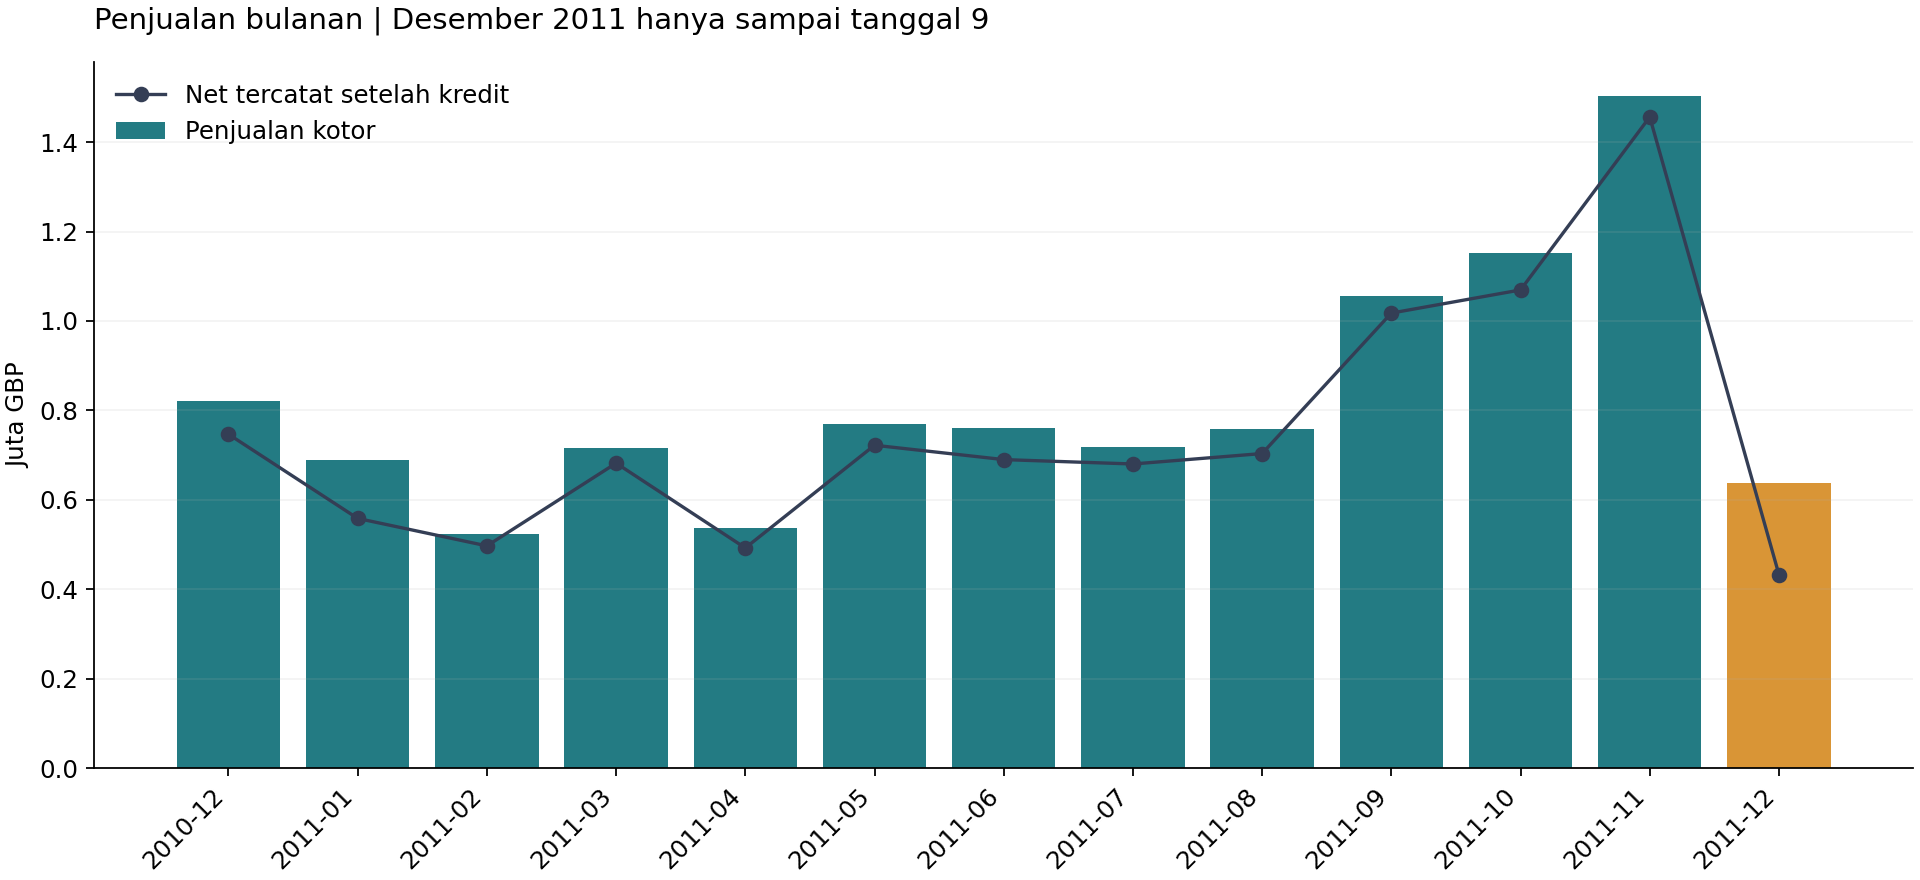

In [4]:
monthly_check = sales.groupby(sales["InvoiceDate"].dt.to_period("M")).agg(
    GrossSalesGBP=("LineValueGBP", "sum"), Orders=("InvoiceNo", "nunique")
)
monthly_check["AOV_GBP"] = monthly_check["GrossSalesGBP"] / monthly_check["Orders"]
display(monthly_check.round(2))
display(Image(filename=str(ROOT / "reports/figures/monthly_sales.png")))

## 4. Produk terlaris

Terlaris berdasarkan unit dan nilai penjualan bisa berbeda. Agregasi memakai StockCode, karena deskripsi produk dapat berubah. Untuk ranking ini, kode lima digit dengan akhiran huruf opsional dianggap produk; kode layanan seperti POST, DOT, dan M dikecualikan.

,StockCode,Description,GrossSalesGBP,Units
0,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641
3,47566,PARTY BUNTING,99445.23,18283
4,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
6,23084,RABBIT NIGHT LIGHT,66870.03,30739
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329
8,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
9,79321,CHILLI LIGHTS,54096.36,10302


,StockCode,Description,Units,GrossSalesGBP
1,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
11,22197,POPCORN HOLDER,56898,51334.47
146,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
4,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75
84,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
8,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
6,23084,RABBIT NIGHT LIGHT,30739,66870.03
114,22492,MINI PAINT SET VINTAGE,26633,16937.82


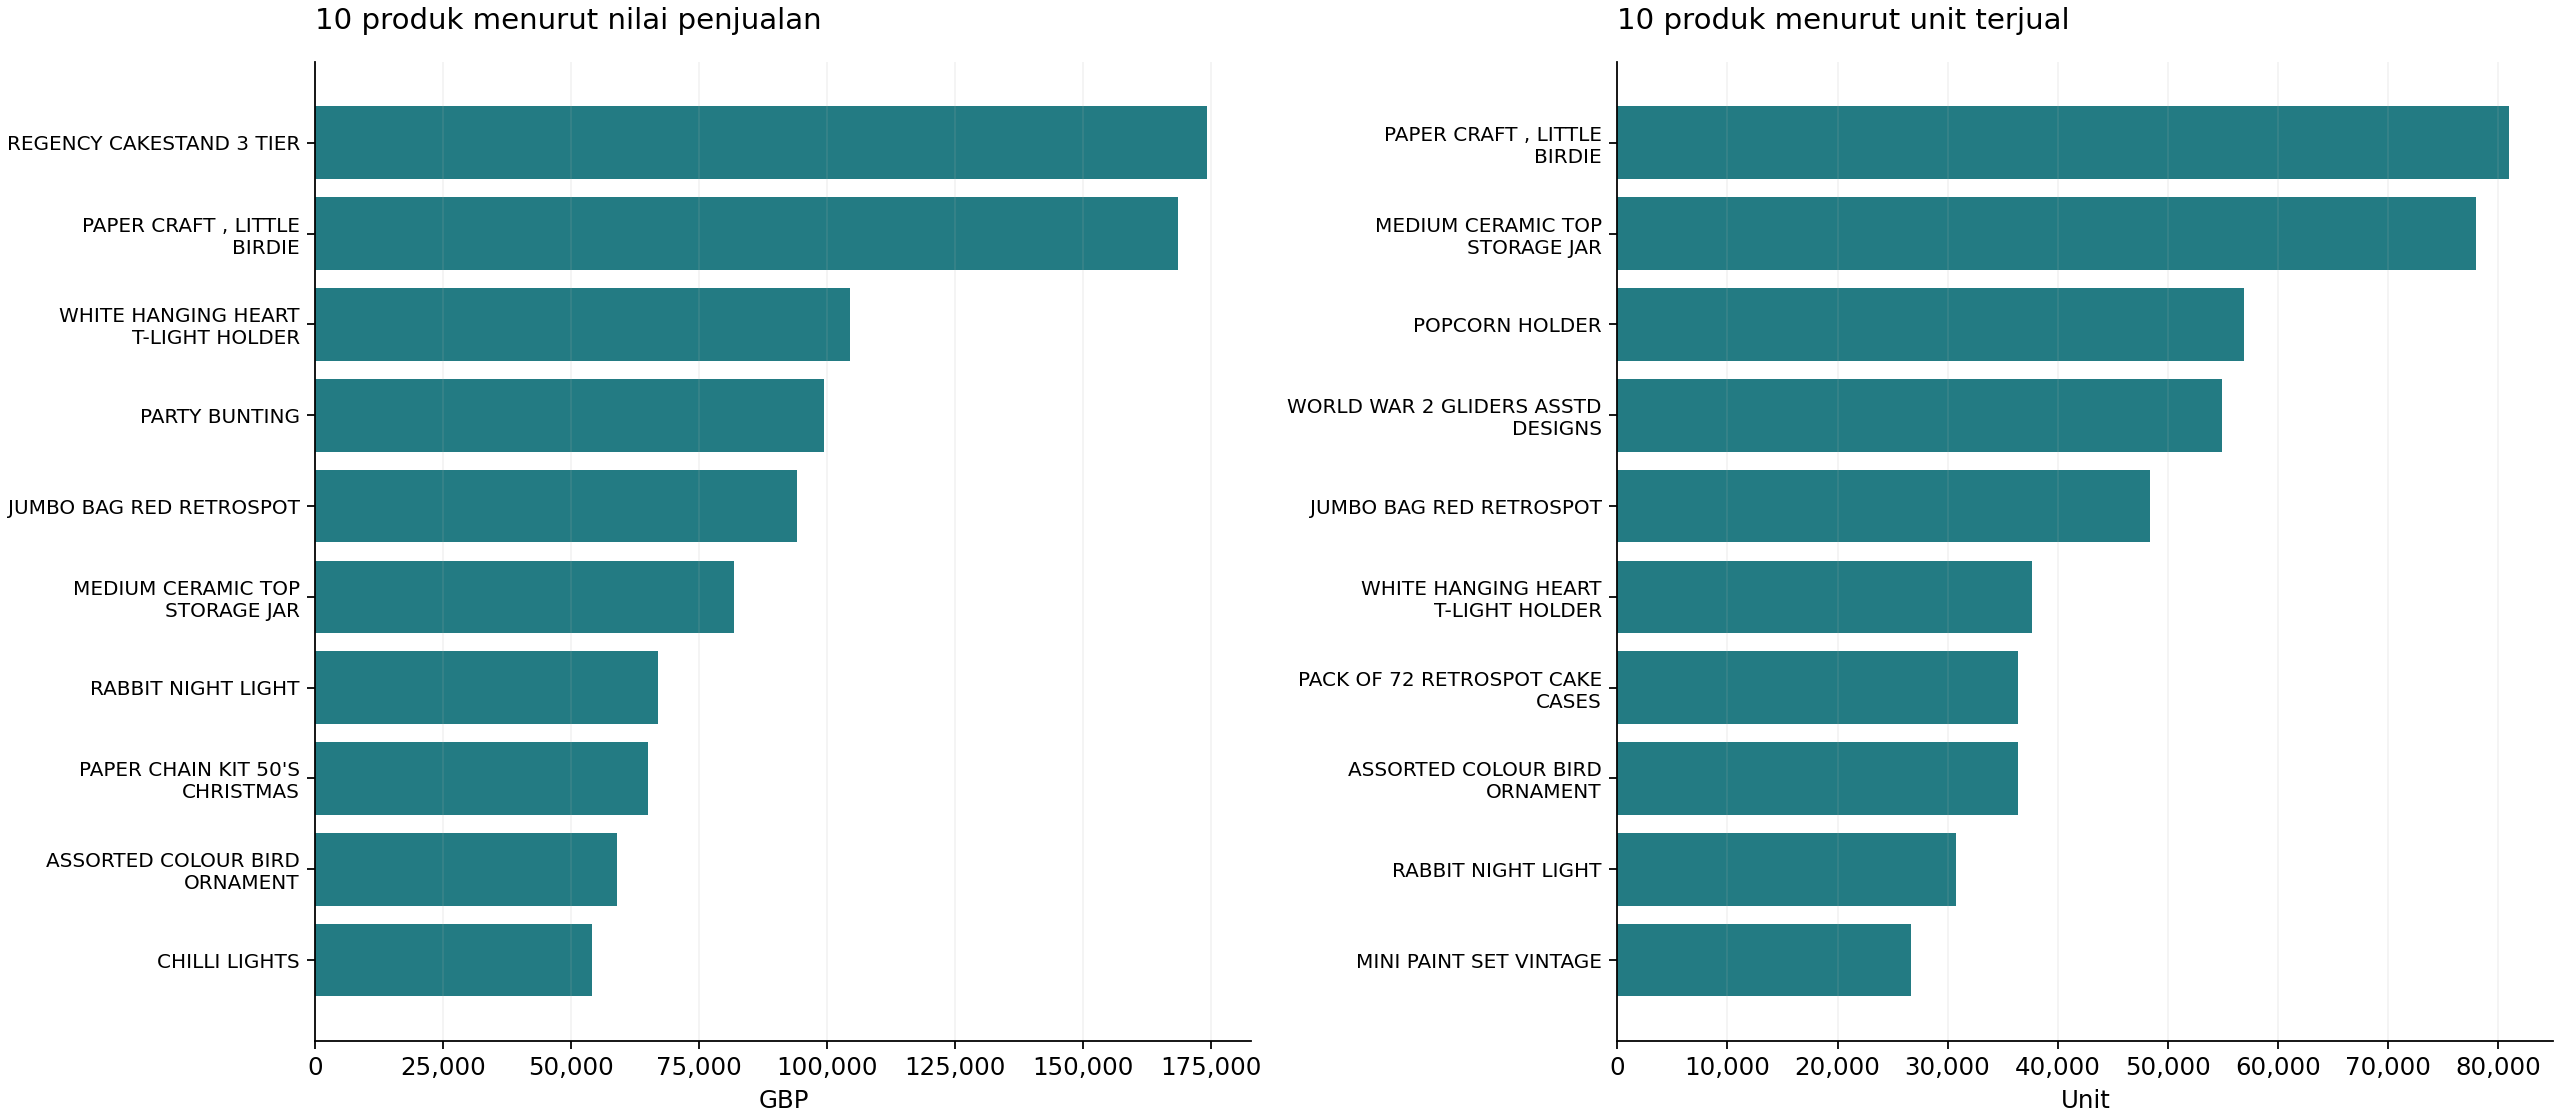

In [5]:
products = pd.read_csv(DATA / "products.csv", dtype={"StockCode": "string"})
display(products.nlargest(10, "GrossSalesGBP")[["StockCode", "Description", "GrossSalesGBP", "Units"]])
display(products.nlargest(10, "Units")[["StockCode", "Description", "Units", "GrossSalesGBP"]])
display(Image(filename=str(ROOT / "reports/figures/top_products.png")))

## 5. Pola belanja dan RFM

Pakai hanya pelanggan dengan CustomerID. Recency = hari sejak pembelian terakhir, Frequency = jumlah invoice penjualan unik, Monetary = gross pada periode observasi. Tanggal acuan adalah sehari setelah tanggal terakhir data sumber. Belanja berulang berarti minimal dua invoice pada periode ini; ini bukan ukuran retensi cohort.

Pelanggan teridentifikasi: 4,338
Pelanggan dengan >=2 invoice: 65.6%


,LastPurchase,Frequency,MonetaryGBP,RecencyDays
CustomerID,,,,
14646,2011-12-08 12:12:00,73,280206.02,2
18102,2011-12-09 11:50:00,60,259657.30,1
17450,2011-12-01 13:29:00,46,194390.79,9
16446,2011-12-09 09:15:00,2,168472.50,1
14911,2011-12-08 15:54:00,201,143711.17,2
12415,2011-11-15 14:22:00,21,124914.53,25
14156,2011-11-30 10:54:00,55,117210.08,10
17511,2011-12-07 10:12:00,31,91062.38,3
16029,2011-11-01 10:27:00,63,80850.84,39


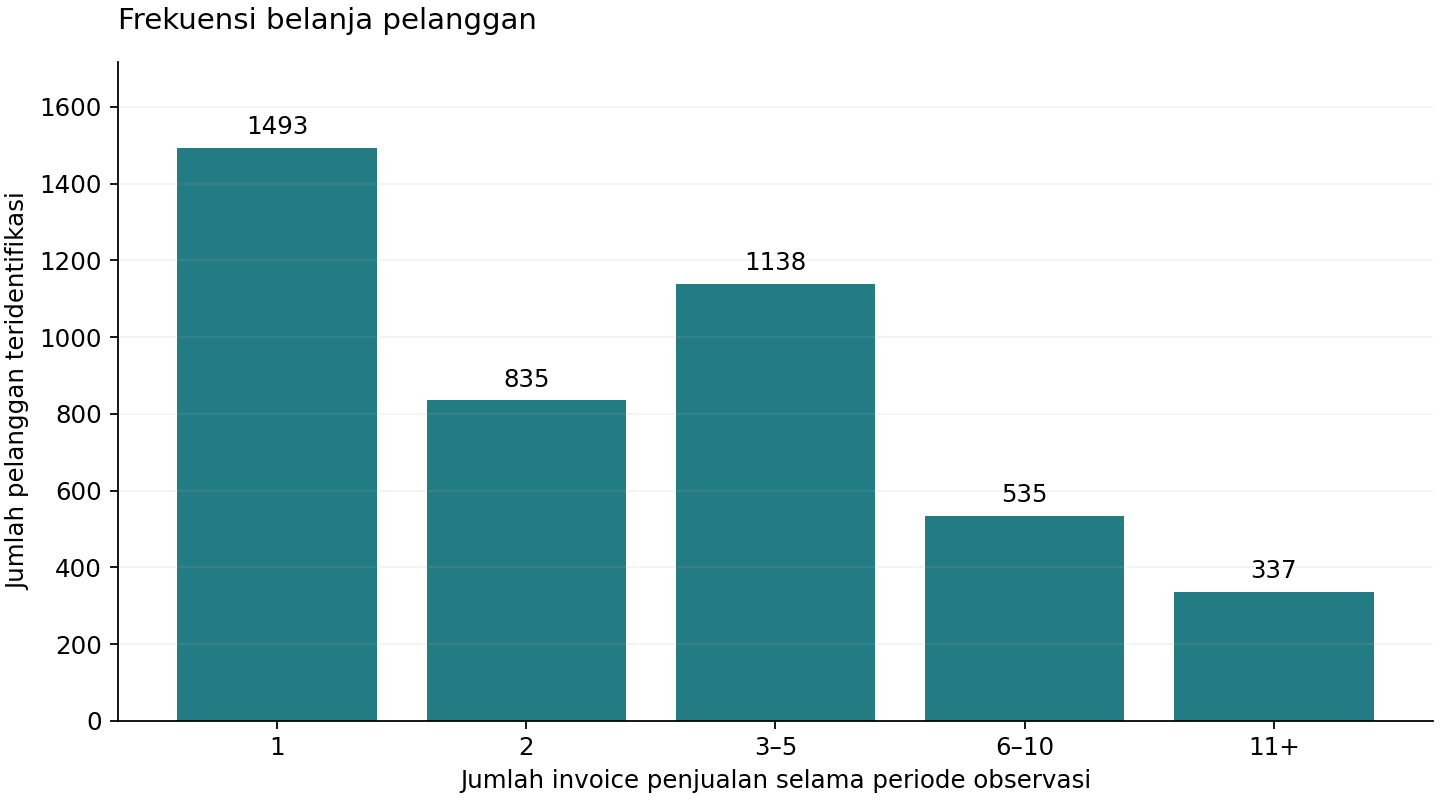

In [6]:
known = sales.dropna(subset=["CustomerID"])
reference = pd.Timestamp(summary["rfm_reference_date"])
rfm = known.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    MonetaryGBP=("LineValueGBP", "sum"),
)
rfm["RecencyDays"] = (reference - rfm["LastPurchase"].dt.normalize()).dt.days
repeat = rfm["Frequency"].ge(2).mean() * 100
print(f"Pelanggan teridentifikasi: {len(rfm):,}")
print(f"Pelanggan dengan >=2 invoice: {repeat:.1f}%")
display(rfm.sort_values("MonetaryGBP", ascending=False).head(10))
display(Image(filename=str(ROOT / "reports/figures/customer_frequency.png")))

## 6. Memeriksa perhitungan

Jumlah nilai bulanan harus sama dengan jumlah nilai baris. Jumlah monetary pelanggan harus sama dengan gross untuk baris yang memiliki CustomerID. Perbedaan dapat menandakan filter atau agregasi yang keliru.

In [7]:
import math
assert math.isclose(monthly_check["GrossSalesGBP"].sum(), gross, abs_tol=0.01)
assert math.isclose(rfm["MonetaryGBP"].sum(), known["LineValueGBP"].sum(), abs_tol=0.01)
assert orders == summary["orders"]
assert math.isclose(gross, summary["gross_sales_gbp"], abs_tol=0.01)
print("Rekonsiliasi penjualan bulanan dan pelanggan berhasil.")

Rekonsiliasi penjualan bulanan dan pelanggan berhasil.


## 7. Latihan interpretasi

1. Apakah produk dengan unit terbanyak juga memiliki nilai penjualan tertinggi? Jelaskan peran harga.
2. Hitung median nilai invoice dan bandingkan dengan rata-ratanya. Apa pengaruh pesanan besar?
3. Ulangi tren bulanan untuk United Kingdom saja.
4. Bandingkan pesanan dan AOV untuk menjelaskan bulan dengan penjualan tertinggi.

Baca laporan `reports/hasil_analisis.md` untuk hasil awal dan batasan. Langkah selanjutnya dapat berupa dashboard atau segmentasi pelanggan setelah pertanyaan analisisnya jelas.